# 05 - ML Pipeline: Customer Churn Prediction
**Dataset:** Indian Netflix Churn Dataset
**Models:** Logistic Regression | Decision Tree | Random Forest | XGBoost

In [3]:
%pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   -----------------

In [5]:
import sys
sys.path.append('..')
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_loader import load_dataset, validate_dataset, get_churn_summary, identify_features
from src.preprocessor import clean_data, encode_target, encode_features, scale_features, split_data
from src.model_trainer import train_all_models, get_best_model, save_model, predict_churn
from src.recommendation_engine import apply_recommendations, get_recommendation_summary

DATA_PATH = '../data/indian_netflix_churn_dataset_v2.csv'

## Step 1 — Load & Validate

In [7]:
df = load_dataset("E:\MCA\SEM 3\Project\Customer_churn_prediction\customer_churn_project\data\indian_netflix_churn_dataset_v2.csv")
print(df.head(3).to_string())

Loaded: 10,000 rows x 22 columns
   Customer_ID  Customer_Name  Gender  Age          State     City           Occupation  Monthly_Income Subscription_Plan  Monthly_Fee  Tenure_Months  Watch_Hours_Per_Month Favorite_Genre Device_Type Payment_Method  Customer_Satisfaction  Support_Tickets  Buffering_Complaints  Concurrent_Screens  Recommendation_Clicks  Churn       Churn_Type
0       100001    Turvi Comar    Male   40      Karnataka   Mysore  Government Employee           57333            Mobile          149             46                     29          Crime      Tablet     Debit Card                      3                3                     9                   2                     16      0  Active Customer
1       100002  Nathan Pingle  Female   43  Uttar Pradesh   Kanpur              Student          265786             Basic          199             44                     26    Documentary    Smart TV        PhonePe                      5                3                     1   

In [8]:
report = validate_dataset(df)
summary = get_churn_summary(df)

Records: 10,000 | Duplicates: 0 | Missing: 0
  total_customers: 10000
  active_customers: 6858
  churned_customers: 3142
  churn_rate_pct: 31.42


## Step 2 — Preprocessing

In [9]:
df = clean_data(df)
df = encode_target(df)
features = identify_features(df)

Removed 0 duplicates
Missing after cleaning: 0
Target — Active(0): 6,858 | Churned(1): 3,142
Numerical  (10): ['Age', 'Monthly_Income', 'Monthly_Fee', 'Tenure_Months', 'Watch_Hours_Per_Month', 'Customer_Satisfaction', 'Support_Tickets', 'Buffering_Complaints', 'Concurrent_Screens', 'Recommendation_Clicks']
Categorical(8): ['Gender', 'State', 'City', 'Occupation', 'Subscription_Plan', 'Favorite_Genre', 'Device_Type', 'Payment_Method']


In [10]:
df = encode_features(df, features['categorical'], save_dir='../models')
df = scale_features(df, features['numerical'],   save_dir='../models')

Encoded 8 categorical columns
Scaled 10 numerical columns


In [11]:
all_features = features['numerical'] + features['categorical']
X_train, X_test, y_train, y_test = split_data(df, all_features)

Train: 8,000 | Test: 2,000


## Step 3 — Train All Models

In [12]:
trained_models = train_all_models(X_train, y_train)

Trained: Logistic Regression
Trained: Decision Tree
Trained: Random Forest
Trained: XGBoost


## Step 4 — Evaluate & Select Best

In [13]:
best_name, best_model, comparison = get_best_model(trained_models, X_test, y_test)
save_model(best_model, best_name, save_dir='../models')
comparison


Model Comparison:
              model  accuracy  precision  recall  f1_score  roc_auc
      Decision Tree    100.00     100.00  100.00    100.00    100.0
      Random Forest     99.80     100.00   99.36     99.68    100.0
            XGBoost    100.00     100.00  100.00    100.00    100.0
Logistic Regression     89.15      83.97   80.89     82.40     95.0

Best Model: Decision Tree
Saved: ../models\decision_tree.pkl


,model,accuracy,precision,recall,f1_score,roc_auc
0,Decision Tree,100.00,100.00,100.00,100.00,100.0
1,Random Forest,99.80,100.00,99.36,99.68,100.0
2,XGBoost,100.00,100.00,100.00,100.00,100.0
3,Logistic Regression,89.15,83.97,80.89,82.40,95.0


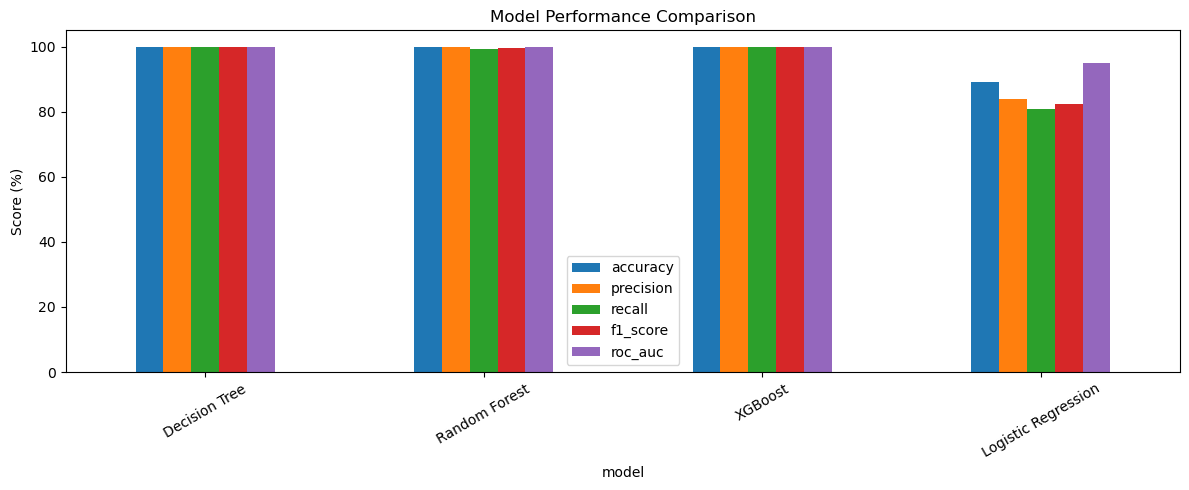

In [14]:
ax = comparison.set_index('model')[['accuracy','precision','recall','f1_score','roc_auc']].plot(
    kind='bar', figsize=(12,5), title='Model Performance Comparison')
plt.ylabel('Score (%)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig('../outputs/model_comparison.png', dpi=150)
plt.show()

## Step 5 — Predictions & Risk Levels

In [15]:
X_all = df[all_features]
preds = predict_churn(best_model, X_all)
df_result = df.copy()
df_result['Churn_Probability'] = preds['Churn_Probability']
df_result['Risk_Level']        = preds['Risk_Level']
print(df_result[['Churn','Churn_Probability','Risk_Level']].head(10))

   Churn  Churn_Probability Risk_Level
0      0                0.0        Low
1      0                0.0        Low
2      0                0.0        Low
3      0                0.0        Low
4      0                0.0        Low
5      1                1.0       High
6      1                1.0       High
7      0                0.0        Low
8      0                0.0        Low
9      0                0.0        Low


## Step 6 — Recommendations

In [16]:
df_result = apply_recommendations(df_result)
print(df_result[['Risk_Level','Recommendation']].head(5).to_string())
print('\nRisk Summary:')
print(get_recommendation_summary(df_result))

  Risk_Level                                                                                   Recommendation
0        Low  Send thank-you message for continued loyalty. | Notify about new features and upcoming content.
1        Low  Send thank-you message for continued loyalty. | Notify about new features and upcoming content.
2        Low  Send thank-you message for continued loyalty. | Notify about new features and upcoming content.
3        Low  Send thank-you message for continued loyalty. | Notify about new features and upcoming content.
4        Low  Send thank-you message for continued loyalty. | Notify about new features and upcoming content.

Risk Summary:
  Risk_Level  Customer_Count
0        Low            6858
1       High            3142
2     Medium               0


In [17]:
df_result.to_csv('../outputs/predictions_with_recommendations.csv', index=False)
print('Saved to outputs/predictions_with_recommendations.csv')

Saved to outputs/predictions_with_recommendations.csv


## Step 7 — SHAP Explainability

In [18]:
try:
    import shap
    explainer   = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(X_test)
    shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
    plt.tight_layout()
    plt.savefig('../outputs/shap_summary.png', dpi=150)
    plt.show()
    print('SHAP chart saved.')
except Exception as e:
    print(f'SHAP skipped: {e}')

SHAP skipped: No module named 'shap'
